# Supplemental Figure 2, Panel L

Proportion of tissue-specific genes (tau index ≥ 0.8) among top 15 BAF-dep features compared to all other features in HepG2 

*Output: PanelL.pdf*

# Setup

In [1]:
# load packages
library(tidyverse)
library(here)
here::i_am("figures/SuppFig2/PanelL/PanelL.ipynb")

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig2/PanelL

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2      lubridate_1.9.4 forcats_1.0.0   stringr_1.5.1  
 [5] dplyr_1.1.4     purrr_1.0.2     readr_2.1.5     tidyr_1.3.1    
 [9] tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] pillar_1.9.0      compiler_4.2.2    base64enc_0.1-3   

# Load data

In [2]:
#read in tau index values (derived from GTEx adult tissue expression)
tau <- read.delim(
  here(
    "figures", "Figure2", "tau",
    "GENCODE_GTex_Tau.tsv"
  ),
  sep = "\t"
)

#read in HepG2 feature importance metrics 
hepg2 <- read.delim(
  here(
    "inputs", "ReModEx", "HepG2", "enh_only",
    "feature_importance.csv"
  ),
  sep = ","
) %>%
  rename("gene_name" = "feature")
#add tau scores to feature importance table
hepg2_tau <- left_join(hepg2,tau, by="gene_name") %>% na.omit()

# Calculate proportions of tissue-specific features

In [3]:
#determine # of features in the top 15 BAF-dependent set (by Ridge coefficient) as well as which features correspond
#to genes with tissue-restricted expression patterns (tau >= 0.8)
#determine # of tissue-restricted genes in top-15 set and in remaining features
hepg2_tau  %>% arrange(Ridge_coef) %>% 
    mutate(index=seq(1,nrow(hepg2_tau)), 
           top_15=index<=15, 
           tissue_restricted=tau_log2 >=0.8) %>%
 group_by(top_15, tissue_restricted) %>% summarize(n=n()) 

`summarise()` has grouped output by 'top_15'. You can override using the
`.groups` argument.


top_15,tissue_restricted,n
<lgl>,<lgl>,<int>
FALSE,FALSE,664
FALSE,TRUE,23
TRUE,FALSE,12
TRUE,TRUE,3


# Generate plot

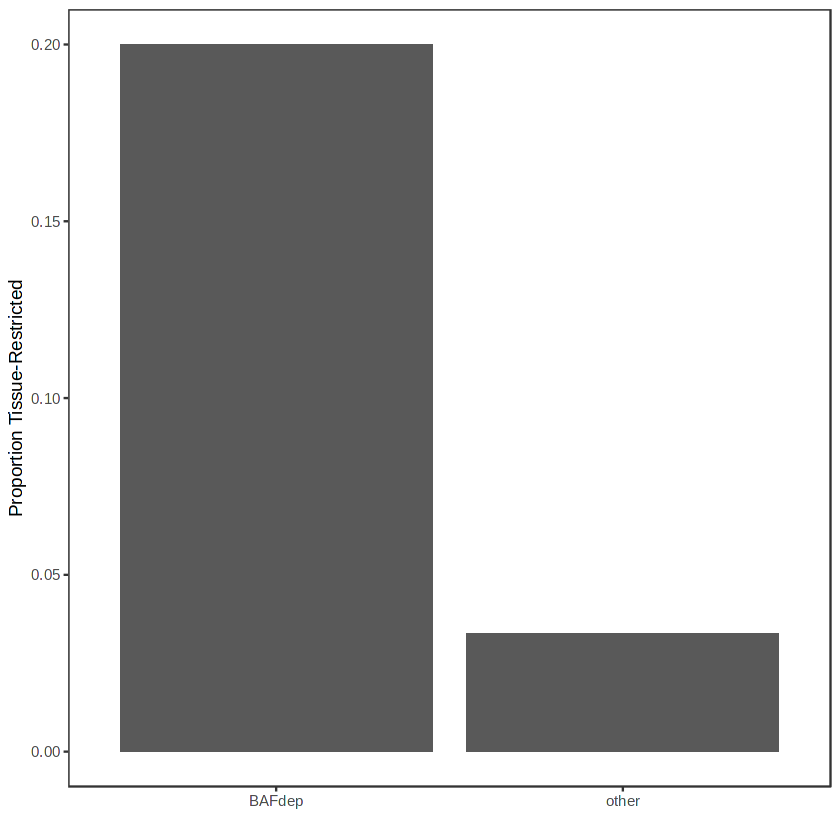

In [4]:
#plot proportion of tissue-restricted genes in background feature set
ggplot(data=NULL) + 
    theme_bw() + theme(panel.grid=element_blank()) + 
    geom_col(aes(x='other', y=23/687)) + geom_col(aes(x='BAFdep', y=3/15)) +
    ylab("Proportion Tissue-Restricted") + xlab('')
ggsave("PanelL.pdf", width=2, height=3)

# Statistics

In [5]:
#Fisher's exact test for enrichment of tissue-restricted genes in BAF-dep features:
hepg2_tau  %>% arrange(Ridge_coef) %>% 
    mutate(index=seq(1,nrow(hepg2_tau)), 
           top_15=index<=15, 
           tissue_restricted=tau_log2 >=0.8) %>%
    select(top_15, tissue_restricted) %>%
    table() %>%
    fisher.test()


	Fisher's Exact Test for Count Data

data:  .
p-value = 0.01528
alternative hypothesis: true odds ratio is not equal to 1
95 percent confidence interval:
  1.216661 29.209473
sample estimates:
odds ratio 
  7.167169 
